In [16]:

pip install shap

Note: you may need to restart the kernel to use updated packages.


In [17]:
# Day 29 — setup, cleaning, split, model, and baseline AUC
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import roc_auc_score, accuracy_score
from xgboost import XGBClassifier

RANDOM_STATE = 42
DATA_PATH = Path("titanic.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place titanic.csv beside this notebook, or update DATA_PATH to its location."
    )

df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()

# Support common Titanic CSV variants while preserving the task-sheet feature names.
if "survived" not in df.columns and "survival" in df.columns:
    df = df.rename(columns={"survival": "survived"})
if "pclass" not in df.columns and "passengerclass" in df.columns:
    df = df.rename(columns={"passengerclass": "pclass"})

required = {"survived", "pclass", "age", "sibsp", "parch", "fare"}
missing = required - set(df.columns)
if missing:
    raise ValueError(
        f"Missing columns: {sorted(missing)}. Check your Days 27–28 cleaning recipe "
        "and map the dataset's column names to the task-sheet names."
    )

# Create numeric sex_male. If it already exists, keep it.
if "sex_male" not in df.columns:
    if "sex" not in df.columns:
        raise ValueError("Need either a 'sex' column or an existing 'sex_male' column.")
    df["sex_male"] = (
        df["sex"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
    )

df["sex_male"] = pd.to_numeric(df["sex_male"], errors="coerce")
df["pclass"] = pd.to_numeric(df["pclass"], errors="coerce")
for col in ["age", "sibsp", "parch", "fare", "survived"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Required age imputation: median within passenger class and sex groups.
df["age"] = df.groupby(["pclass", "sex_male"])["age"].transform(
    lambda s: s.fillna(s.median())
)
# Fallback if a group had no observed age.
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

model_df = df[features + [target]].dropna().copy()
X = model_df[features].astype(float)
y = model_df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    n_jobs=-1
)
model.fit(X_train, y_train)

test_prob = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_prob)

print("Rows used:", len(model_df))
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print(f"Test ROC-AUC: {test_auc:.4f}")
print("Features:", features)

Rows used: 1000
Train rows: 800 | Test rows: 200
Test ROC-AUC: 0.8452
Features: ['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare']


### Setup — what this cell does

- Loads `titanic.csv`, standardizes column names, and checks the required columns.
- Creates `sex_male` as `1 = male` and `0 = female`.
- Fills missing age values with the median for the same passenger class and sex, then uses the overall age median as a fallback. Missing fares are filled with the fare median.
- Makes a stratified 80/20 split with `random_state=42`, trains the required XGBoost model, and prints test ROC-AUC.
- **Important:** use the same cleaning and split as Days 27–28. If their recipe differs, reuse it here so comparisons remain fair.

**Why AUC?** ROC-AUC measures how well the model ranks survivors above non-survivors across probability thresholds. It is a global performance metric, not an explanation of an individual prediction.

,mean_auc_drop
sex_male,0.236792
fare,0.046172
pclass,0.040858
parch,0.003257
sibsp,-0.001451
age,-0.006674


Top three permutation drivers, in order: sex_male > fare > pclass


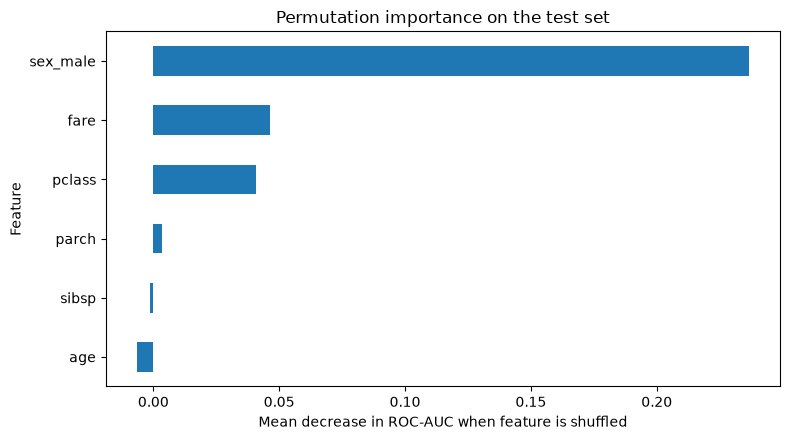

In [18]:
# TASK 01 — Global permutation importance
perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=-1
)

perm_importance = pd.Series(
    perm.importances_mean, index=features, name="mean_auc_drop"
).sort_values(ascending=False)

display(perm_importance.to_frame())
top3_perm = perm_importance.index[:3].tolist()
print("Top three permutation drivers, in order:", " > ".join(top3_perm))

fig, ax = plt.subplots(figsize=(8, 4.5))
perm_importance.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Permutation importance on the test set")
ax.set_xlabel("Mean decrease in ROC-AUC when feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

### Task 01 — Markdown answer

**Global interpretation** describes behavior across many rows. Permutation importance measures how much the test ROC-AUC falls when one feature's values are shuffled. A larger drop suggests the model relies more on that feature for predictive performance.

**Top three drivers:** read the printed ranking from top to third after running the notebook; do not guess the order before seeing your result.

**What can this ranking NOT answer?** It cannot explain why the model gave one specific passenger a high or low survival probability, and it does not show whether high feature values increase or decrease the prediction.

**Look it up — Why shuffle a feature?** Shuffling breaks its relationship with the target while leaving the other columns as they were. If model performance falls, the feature was useful to the fitted model. Correlated features can share information, so one feature may look less important when another can substitute for it.

In [19]:
# TASK 02 — Verify SHAP local accuracy on three rows
explainer = shap.TreeExplainer(model)
shap_values_raw = explainer.shap_values(X_test)

# Normalize SHAP output across common SHAP versions.
if isinstance(shap_values_raw, list):
    # Binary classifiers commonly return the positive-class values as the second item.
    sv = np.asarray(shap_values_raw[-1])
else:
    sv = np.asarray(shap_values_raw)
    if sv.ndim == 3:
        sv = sv[:, :, -1]

base_value = float(np.ravel(explainer.expected_value)[-1])
raw_margin = model.predict(X_test, output_margin=True)
raw_margin = np.asarray(raw_margin).reshape(-1)

print("SHAP values shape:", sv.shape)
print("Expected/base value:", base_value)
print("Expected value means the model's baseline output on the raw-margin (log-odds) scale.")

for i in [0, min(1, len(X_test)-1), min(2, len(X_test)-1)]:
    reconstructed = base_value + sv[i].sum()
    matches = np.isclose(reconstructed, raw_margin[i], rtol=1e-4, atol=1e-4)
    print(
        f"row={i}: base + SHAP sum={reconstructed:.6f}, "
        f"raw margin={raw_margin[i]:.6f}, np.isclose={matches}"
    )

SHAP values shape: (200, 6)
Expected/base value: -0.24494130909442902
Expected value means the model's baseline output on the raw-margin (log-odds) scale.
row=0: base + SHAP sum=2.261753, raw margin=2.261752, np.isclose=True
row=1: base + SHAP sum=0.274161, raw margin=0.274161, np.isclose=True
row=2: base + SHAP sum=3.649335, raw margin=3.649336, np.isclose=True


### Task 02 — Markdown answer

For this binary model, the usual SHAP array shape is **(number of test rows, number of features)**. Each row contains one contribution for every input feature. The printed shape confirms the actual dimensions in your installed SHAP version.

The **expected value** is the model's baseline output before adding the selected passenger's feature contributions. For a tree classifier explained on the raw-output scale, it is generally a baseline margin/log-odds value.

**Look it up — Why `output_margin=True` rather than `predict_proba`?** Tree SHAP contributions add to the model's raw margin. Probability is a nonlinear sigmoid transformation of that margin, so the individual raw SHAP values generally do not add directly to a probability.

**What if reconstruction fails?** Check whether the correct binary-class SHAP array was selected, the expected value is scalarized correctly, the same rows/features were used, and the explainer/model output settings agree. A mismatch should be investigated rather than described as a valid SHAP explanation.

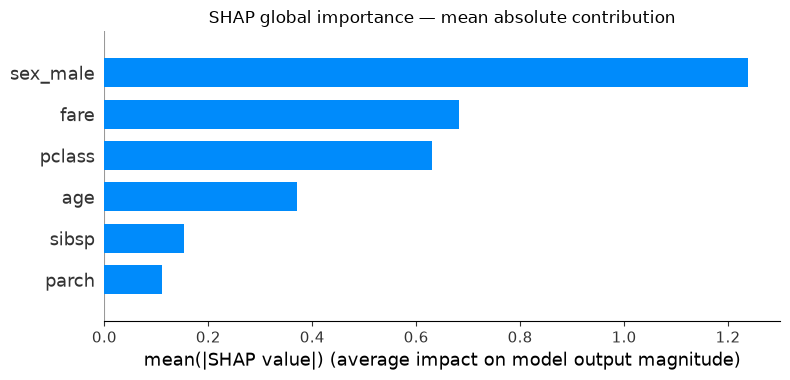

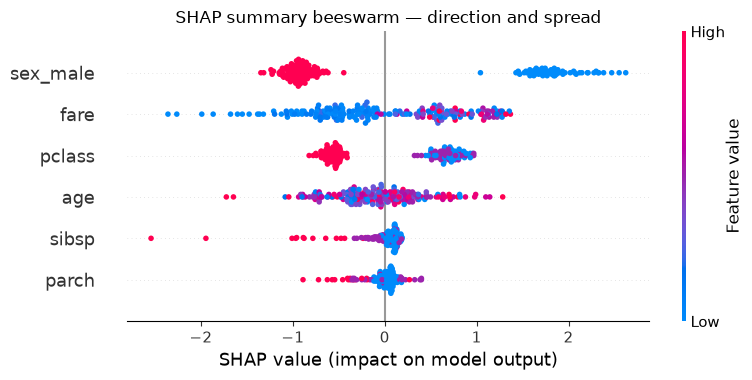

,permutation_importance,mean_abs_shap
sex_male,0.236792,1.238137
fare,0.046172,0.682719
pclass,0.040858,0.630541
age,-0.006674,0.371019
sibsp,-0.001451,0.153484
parch,0.003257,0.111172


Top two SHAP features: ['sex_male', 'fare']
sex_male=0: mean SHAP=1.8293
sex_male=1: mean SHAP=-0.9336
fare: mean SHAP for low (<= 9.57) values=-0.8494; high (>= 64.2) values=0.8196


In [20]:
# TASK 03 — SHAP global bar and beeswarm plots
shap_exp = shap.Explanation(
    values=sv,
    base_values=np.repeat(base_value, len(X_test)),
    data=X_test.to_numpy(),
    feature_names=features
)

plt.figure()
shap.summary_plot(sv, X_test, plot_type="bar", show=False)
plt.title("SHAP global importance — mean absolute contribution")
plt.tight_layout()
plt.show()

plt.figure()
shap.summary_plot(sv, X_test, show=False)
plt.title("SHAP summary beeswarm — direction and spread")
plt.tight_layout()
plt.show()

shap_importance = pd.Series(
    np.abs(sv).mean(axis=0), index=features, name="mean_abs_shap"
).sort_values(ascending=False)
display(pd.concat(
    [perm_importance.rename("permutation_importance"), shap_importance],
    axis=1
).sort_values("mean_abs_shap", ascending=False))

top2_shap = shap_importance.index[:2].tolist()
print("Top two SHAP features:", top2_shap)

# Numerical aid for interpreting direction; always verify using the beeswarm colors.
for feat in top2_shap:
    j = features.index(feat)
    vals = X_test[feat].to_numpy()
    contrib = sv[:, j]
    if X_test[feat].nunique() <= 2:
        for level in sorted(pd.Series(vals).dropna().unique()):
            print(f"{feat}={level:g}: mean SHAP={contrib[vals == level].mean():.4f}")
    else:
        lo, hi = np.quantile(vals, [0.2, 0.8])
        print(
            f"{feat}: mean SHAP for low (<= {lo:.3g}) values="
            f"{contrib[vals <= lo].mean():.4f}; "
            f"high (>= {hi:.3g}) values={contrib[vals >= hi].mean():.4f}"
        )

### Task 03 — Markdown answer

The SHAP **bar plot** ranks features by mean absolute SHAP value. It shows typical contribution size but discards sign, the distribution of individual contributions, and the feature values associated with them.

The **beeswarm** shows one dot per row and feature. Horizontal position is the SHAP contribution (right generally pushes the raw model output toward survival; left pushes it away); color represents the feature value (usually red/pink = high and blue = low). The spread shows how much a feature's effect varies across passengers.

Compare the SHAP ranking to Task 01's permutation ranking using the displayed table. They can differ because permutation importance measures the drop in held-out AUC, while SHAP measures contribution magnitude on the model-output scale.

**Look it up — Which ranking should you trust if they disagree?** Neither automatically. First check feature correlation, the evaluation metric, the SHAP output scale, and whether the disagreement is stable across folds or resamples.

**Why two tight clusters for `sex_male`?** It is binary, so it has only two possible feature values, 0 and 1. The SHAP positions can still vary vertically or horizontally because other passenger characteristics and interactions differ.


 Most confident survival | test row index: 133
pclass       1.00
sex_male     0.00
age         36.50
sibsp        0.00
parch        0.00
fare        80.28
Actual survived: 1
Predicted survival probability: 0.9935
Largest contributions: sex_male pushed toward survival (SHAP=+2.145); fare pushed toward survival (SHAP=+1.110); age pushed toward survival (SHAP=+1.100)


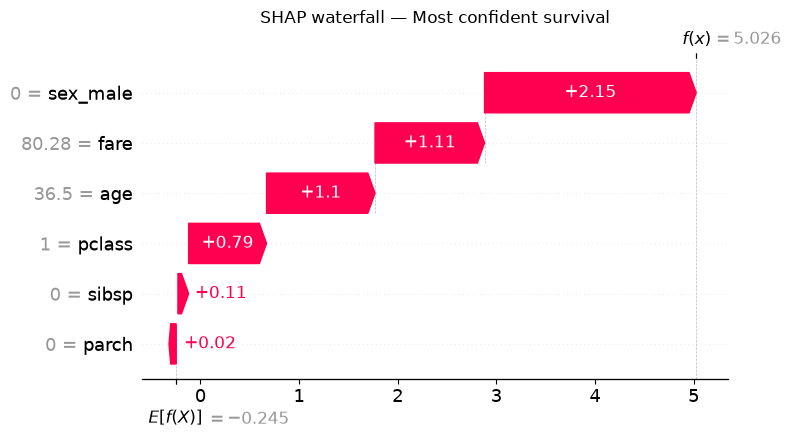


 Most confident death | test row index: 103
pclass       3.00
sex_male     1.00
age         22.60
sibsp        4.00
parch        0.00
fare         7.66
Actual survived: 0
Predicted survival probability: 0.0014
Largest contributions: sibsp pushed away from survival (SHAP=-2.542); fare pushed away from survival (SHAP=-1.990); sex_male pushed away from survival (SHAP=-1.133)


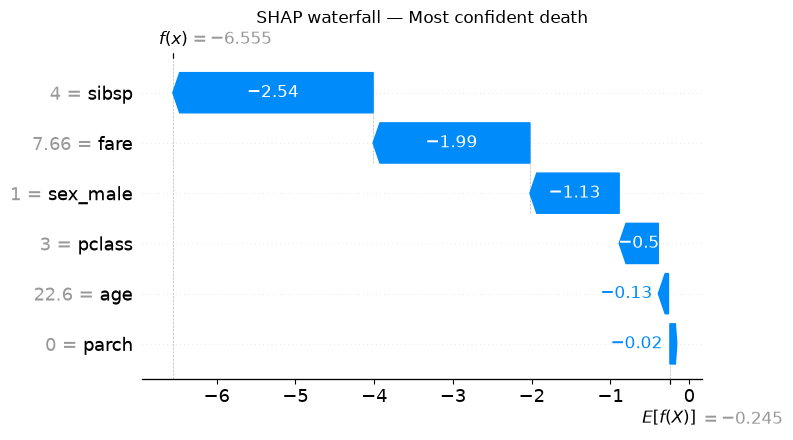


 Closest to 0.50 | test row index: 106
pclass       3.00
sex_male     0.00
age         23.80
sibsp        0.00
parch        0.00
fare         6.64
Actual survived: 1
Predicted survival probability: 0.4980
Largest contributions: sex_male pushed toward survival (SHAP=+1.844); fare pushed away from survival (SHAP=-0.957); pclass pushed away from survival (SHAP=-0.544)


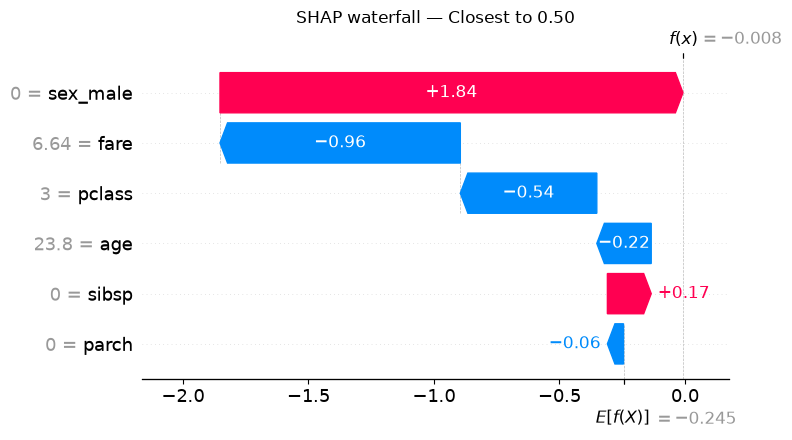


Uncertain passenger SHAP values:
sex_male    1.844361
fare       -0.957422
pclass     -0.543742
age        -0.216795
sibsp       0.174665
parch      -0.064272
dtype: float32


In [21]:
# TASK 04 — Select three passengers and create waterfall plots
probs = model.predict_proba(X_test)[:, 1]
most_confident_survival_idx = int(np.argmax(probs))
most_confident_death_idx = int(np.argmin(probs))
uncertain_idx = int(np.argmin(np.abs(probs - 0.50)))

selected = [
    ("Most confident survival", most_confident_survival_idx),
    ("Most confident death", most_confident_death_idx),
    ("Closest to 0.50", uncertain_idx)
]

def make_row_explanation(idx):
    row_values = X_test.iloc[idx]
    row_sv = sv[idx]
    order = np.argsort(np.abs(row_sv))[::-1]
    parts = []
    for j in order[:3]:
        direction = "pushed toward survival" if row_sv[j] > 0 else "pushed away from survival"
        parts.append(f"{features[j]} {direction} (SHAP={row_sv[j]:+.3f})")
    return "; ".join(parts)

for label, idx in selected:
    print("\n", label, "| test row index:", idx)
    print(X_test.iloc[idx].to_string())
    print(f"Actual survived: {int(y_test.iloc[idx])}")
    print(f"Predicted survival probability: {probs[idx]:.4f}")
    print("Largest contributions:", make_row_explanation(idx))
    one_exp = shap.Explanation(
        values=sv[idx],
        base_values=base_value,
        data=X_test.iloc[idx].to_numpy(),
        feature_names=features
    )
    shap.plots.waterfall(one_exp, max_display=len(features), show=False)
    plt.title(f"SHAP waterfall — {label}")
    plt.tight_layout()
    plt.show()

print("\nUncertain passenger SHAP values:")
print(pd.Series(sv[uncertain_idx], index=features).sort_values(key=np.abs, ascending=False))

### Task 04 — Markdown answer

The notebook chooses passengers from the model's actual test predictions:
- **Most confident survival:** the largest predicted survival probability.
- **Most confident death:** the smallest predicted survival probability.
- **Uncertain:** the probability closest to 0.50.

A waterfall starts at the base value and adds/subtracts each feature's SHAP contribution until it reaches that passenger's model output. The printed top contributions help translate the plot into plain language.

For each passenger, write two or three sentences using the actual printed probability and the largest positive and negative SHAP values. For the uncertain passenger, compare the signs and magnitudes: large contributions in both directions indicate mixed evidence; tiny contributions overall indicate weak evidence. Use the printed numbers to decide which description fits your run.

**Required conclusion:** Do not claim the uncertain passenger has mixed evidence until the SHAP values show meaningful contributions in both directions. The values are in raw-margin units, not percentage points of probability.

<Figure size 700x500 with 0 Axes>

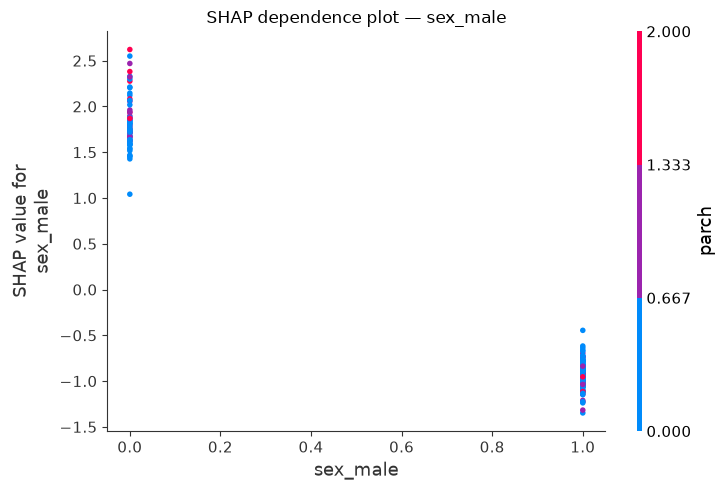


sex_male: correlation between feature value and SHAP contribution = -0.988


<Figure size 700x500 with 0 Axes>

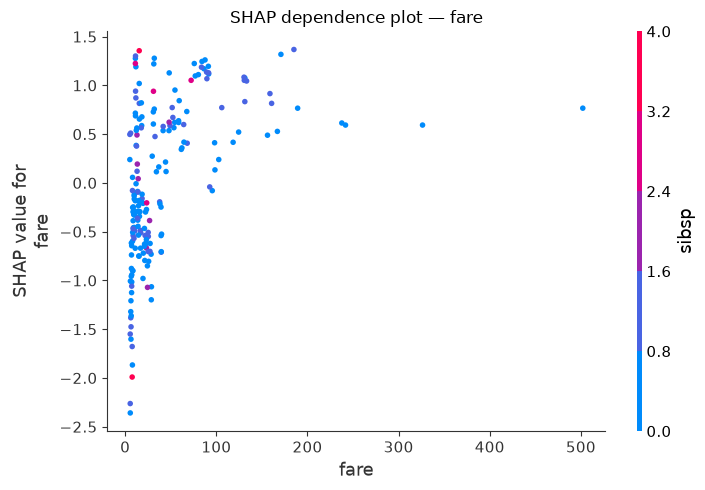


fare: correlation between feature value and SHAP contribution = 0.448


In [22]:
# TASK 05 — SHAP dependence plots for the top two features
for feat in top2_shap:
    plt.figure(figsize=(7, 5))
    shap.dependence_plot(
        feat, sv, X_test,
        interaction_index="auto",
        show=False
    )
    plt.title(f"SHAP dependence plot — {feat}")
    plt.tight_layout()
    plt.show()

    j = features.index(feat)
    values = X_test[feat].to_numpy()
    contributions = sv[:, j]
    print(f"\n{feat}: correlation between feature value and SHAP contribution = "
          f"{np.corrcoef(values, contributions)[0, 1]:.3f}")

### Task 05 — Markdown answer

A SHAP dependence plot puts a feature's actual value on the x-axis and its SHAP contribution on the y-axis. Describe the observed shape from your plot: approximately linear, rising then flattening, falling, threshold-like, or irregular. Do not decide the shape before inspecting the chart.

The point color is the feature SHAP automatically selects as a possible interaction partner. Name the color-bar feature shown in each plot and check whether different colors at similar x-values line up with different SHAP values.

**What does vertical spread at the same x-value mean?** Passengers with similar values of the selected feature receive different contributions. Other features or interactions may explain part of that difference; it is a clue, not by itself proof of causation.

Features for PDPs: ['sex_male', 'fare', 'pclass']


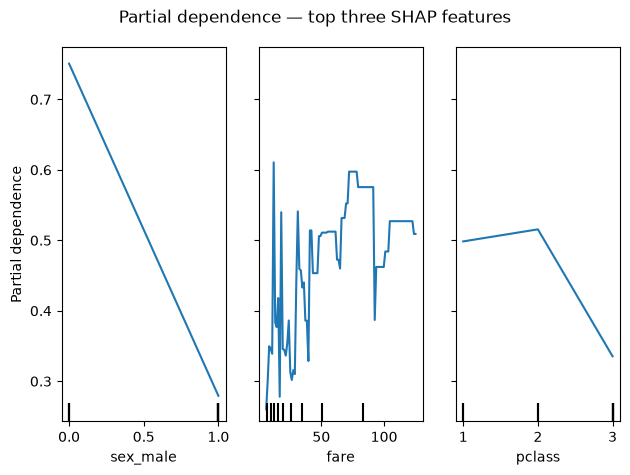

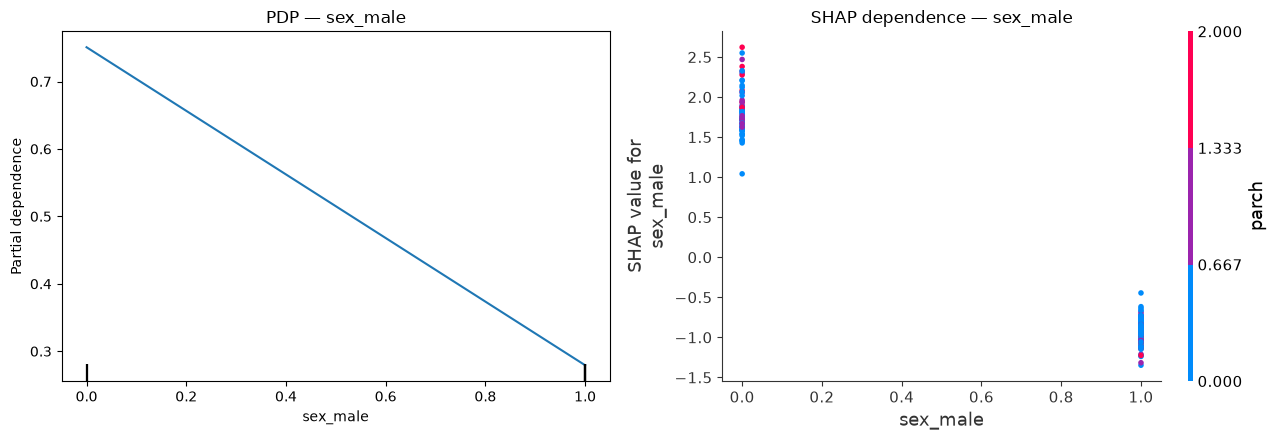

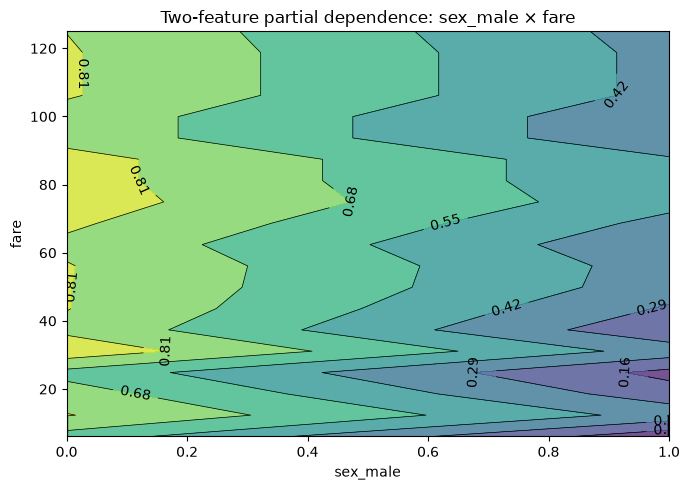

,Question,SHAP dependence,PDP
0,What does each dot or line represent?,Each dot is one passenger; x is feature value ...,The line is the average model prediction as th...
1,Is individual spread visible?,Yes: variation across dots is visible.,No: individual passenger variation is averaged...
2,Are interactions visible?,Potentially: color encodes another feature sel...,A two-feature PDP shows average predictions ov...
3,Which is easier for a non-technical reader?,"Useful for debugging, but needs explanation of...",Often easier to explain as average predicted o...


In [23]:
# TASK 06 — Partial dependence plots (PDPs) and comparison
top3_features = shap_importance.index[:3].tolist()
print("Features for PDPs:", top3_features)

PartialDependenceDisplay.from_estimator(
    model, X_train, features=top3_features, kind="average"
)
plt.gcf().suptitle("Partial dependence — top three SHAP features")
plt.tight_layout()
plt.show()

# Put the top feature's PDP beside its SHAP dependence plot.
top_feature = top3_features[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
PartialDependenceDisplay.from_estimator(
    model, X_train, features=[top_feature], ax=axes[0], kind="average"
)
axes[0].set_title(f"PDP — {top_feature}")
shap.dependence_plot(
    top_feature, sv, X_test, interaction_index="auto", ax=axes[1], show=False
)
axes[1].set_title(f"SHAP dependence — {top_feature}")
plt.tight_layout()
plt.show()

# Two-feature PDP contour. The tuple requests a joint grid over two features.
pair = (top3_features[0], top3_features[1])
fig, ax = plt.subplots(figsize=(7, 5))
PartialDependenceDisplay.from_estimator(
    model, X_train, features=[pair], ax=ax, kind="average", grid_resolution=20
)
ax.set_title(f"Two-feature partial dependence: {pair[0]} × {pair[1]}")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Question": [
        "What does each dot or line represent?",
        "Is individual spread visible?",
        "Are interactions visible?",
        "Which is easier for a non-technical reader?"
    ],
    "SHAP dependence": [
        "Each dot is one passenger; x is feature value and y is that passenger's SHAP contribution.",
        "Yes: variation across dots is visible.",
        "Potentially: color encodes another feature selected as an interaction candidate.",
        "Useful for debugging, but needs explanation of SHAP values and colors."
    ],
    "PDP": [
        "The line is the average model prediction as the selected feature varies; other features are averaged over.",
        "No: individual passenger variation is averaged away.",
        "A two-feature PDP shows average predictions over a pair of features.",
        "Often easier to explain as average predicted outcome versus feature value."
    ]
})
display(comparison)

### Task 06 — Markdown answer

A **partial dependence plot (PDP)** estimates the model's average prediction as one feature changes while averaging over the other features. The two-feature PDP is a contour/heat map of average predictions across combinations of the two selected features.

Use the actual plots to describe whether the average prediction rises, falls, or flattens and what the contour suggests. PDPs can average over unrealistic combinations of correlated features, so interpret them carefully.

**Suggested report choice:** PDP is often easier for a business audience because it communicates an average prediction trend directly. **Suggested debugging choice:** SHAP dependence is useful because each dot represents an actual passenger and exposes variation hidden by the average. Adjust this recommendation if your own plots make a different trade-off clearer.

In [24]:
# TASK 07 — Correlated features split SHAP credit
original_fare_importance = float(shap_importance["fare"])
print(f"Original fare mean absolute SHAP: {original_fare_importance:.6f}")

rng = np.random.default_rng(RANDOM_STATE)
X_train_dup = X_train.copy()
X_test_dup = X_test.copy()
noise_scale = max(float(X_train["fare"].std()), 1.0) * 1e-4
X_train_dup["fare_copy"] = X_train_dup["fare"] + rng.normal(
    0, noise_scale, size=len(X_train_dup)
)
X_test_dup["fare_copy"] = X_test_dup["fare"] + rng.normal(
    0, noise_scale, size=len(X_test_dup)
)
fare_corr = X_train_dup["fare"].corr(X_train_dup["fare_copy"])
print(f"Correlation between fare and fare_copy: {fare_corr:.6f}")

dup_features = features + ["fare_copy"]
dup_model = XGBClassifier(
    n_estimators=300, learning_rate=0.1, max_depth=3,
    random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1
)
dup_model.fit(X_train_dup[dup_features], y_train)
dup_explainer = shap.TreeExplainer(dup_model)
dup_shap_raw = dup_explainer.shap_values(X_test_dup[dup_features])
if isinstance(dup_shap_raw, list):
    dup_sv = np.asarray(dup_shap_raw[-1])
else:
    dup_sv = np.asarray(dup_shap_raw)
    if dup_sv.ndim == 3:
        dup_sv = dup_sv[:, :, -1]

dup_importance = pd.Series(
    np.abs(dup_sv).mean(axis=0), index=dup_features, name="mean_abs_shap"
)
fare_after = float(dup_importance["fare"])
fare_copy_after = float(dup_importance["fare_copy"])
print(f"fare after duplication:      {fare_after:.6f}")
print(f"fare_copy after duplication: {fare_copy_after:.6f}")
print(f"combined after duplication:  {fare_after + fare_copy_after:.6f}")
display(dup_importance.sort_values(ascending=False).to_frame())

Original fare mean absolute SHAP: 0.682719
Correlation between fare and fare_copy: 1.000000
fare after duplication:      0.505506
fare_copy after duplication: 0.279398
combined after duplication:  0.784904


,mean_abs_shap
sex_male,1.217743
pclass,0.644920
fare,0.505506
age,0.342170
fare_copy,0.279398
sibsp,0.162700
parch,0.106917


### Task 07 — Markdown answer

The experiment adds `fare_copy`, a near-duplicate of `fare`, with tiny random noise. The printed correlation should be above 0.99. The model now has two columns carrying almost the same information.

Compare the original fare importance with the new importance for `fare`, `fare_copy`, and their sum. The split need not be exactly 50/50: tree construction and SHAP allocation can give the two correlated columns unequal credit. The key point is that individual importance can change even though the information available to the model barely changed.

**Look it up — What wrong conclusion could you draw?** You might wrongly conclude that fare became unimportant or that either duplicate is individually less useful, when the two columns are sharing credit.

**Two business examples:** total customer spend and average order value; annual income and monthly income. Other plausible examples include product price and discounted price, or number of support tickets and number of complaints.

**Before reading SHAP importance:** inspect feature correlations, duplicate columns, feature definitions, and data leakage.

**Two-sentence warning:** “SHAP importance can divide credit unpredictably among strongly correlated features. Check correlations and consider the combined importance of related features before concluding that one feature matters less.”

In [25]:
# TASK 08 — Measure TreeExplainer and KernelExplainer cost
# Time TreeExplainer for all test rows.
tree_start = time.perf_counter()
tree_values_timed = explainer.shap_values(X_test)
tree_seconds = time.perf_counter() - tree_start
tree_ms_per_row = 1000 * tree_seconds / len(X_test)

# KernelExplainer is model-agnostic and can be much slower.
background = X_train.sample(n=min(50, len(X_train)), random_state=RANDOM_STATE)
kernel_rows = X_test.iloc[:min(30, len(X_test))]
kernel_explainer = shap.KernelExplainer(
    lambda data: model.predict_proba(pd.DataFrame(data, columns=features))[:, 1],
    background.to_numpy()
)
kernel_start = time.perf_counter()
kernel_values = kernel_explainer.shap_values(
    kernel_rows.to_numpy(), nsamples=100
)
kernel_seconds = time.perf_counter() - kernel_start
kernel_ms_per_row = 1000 * kernel_seconds / len(kernel_rows)

ratio = kernel_ms_per_row / tree_ms_per_row if tree_ms_per_row > 0 else np.inf
estimated_100k_seconds = (kernel_ms_per_row / 1000) * 100_000
estimated_100k_hours = estimated_100k_seconds / 3600

print(f"TreeExplainer total: {tree_seconds:.3f} s; {tree_ms_per_row:.3f} ms/row")
print(f"KernelExplainer total: {kernel_seconds:.3f} s; {kernel_ms_per_row:.3f} ms/row")
print(f"Kernel / Tree per-row time ratio: {ratio:.1f}x")
print(f"Estimated KernelExplainer time for 100,000 rows: {estimated_100k_hours:.2f} hours")

 20%|██        | 6/30 [00:00<00:00, 59.27it/s]

100%|██████████| 30/30 [00:00<00:00, 64.04it/s]

TreeExplainer total: 0.020 s; 0.099 ms/row
KernelExplainer total: 0.467 s; 15.583 ms/row
Kernel / Tree per-row time ratio: 157.9x
Estimated KernelExplainer time for 100,000 rows: 0.43 hours


### Task 08 — Markdown answer

**TreeExplainer** exploits tree structure and is generally the right choice for supported tree models such as XGBoost. **KernelExplainer** can explain many model types but is model-agnostic and often much slower because it estimates contributions through repeated model evaluations.

Use the measured milliseconds per row and ratio printed above. The 100,000-row estimate assumes the measured KernelExplainer rate stays constant; actual runtime depends on hardware, background size, `nsamples`, and model cost.

**One-line rule:** use TreeExplainer for compatible tree models; use KernelExplainer when the model is not supported by a specialized explainer and the cost is acceptable.

**If a non-tree model is very large:** explain a carefully selected representative sample, use a smaller background set, consider a model-appropriate faster explainer, and document the sampling/approximation limits rather than blindly explaining every row.

In [26]:
# TASK 09 — Generate a measured interpretation paragraph template
# Estimate direction for numeric features using low vs high feature-value groups.
direction_notes = {}
for feat in top3_features:
    j = features.index(feat)
    values = X_test[feat].to_numpy()
    contributions = sv[:, j]
    if X_test[feat].nunique() <= 2:
        low_val = np.nanmin(values)
        high_val = np.nanmax(values)
        low_mean = contributions[values == low_val].mean()
        high_mean = contributions[values == high_val].mean()
        direction_notes[feat] = (
            f"the average SHAP contribution was {low_mean:+.3f} at {feat}={low_val:g} "
            f"and {high_mean:+.3f} at {feat}={high_val:g}"
        )
    else:
        q20, q80 = np.quantile(values, [0.2, 0.8])
        low_mean = contributions[values <= q20].mean()
        high_mean = contributions[values >= q80].mean()
        if high_mean > low_mean:
            direction = "higher values tended to push the model output toward survival compared with lower values"
        elif high_mean < low_mean:
            direction = "higher values tended to push the model output away from survival compared with lower values"
        else:
            direction = "the average contributions for high and low values were similar"
        direction_notes[feat] = direction

print(f"Test ROC-AUC = {test_auc:.4f}.")
for rank, feat in enumerate(top3_features, start=1):
    print(f"{rank}. {feat}: {direction_notes[feat]}")

print("""
DRAFT PARAGRAPH — edit this after reviewing the plots:
The Titanic model achieved the test ROC-AUC printed above. Its three highest-ranked SHAP features,
in order, were [insert the three feature names and describe the measured direction from the plots].
The dependence plot for [insert feature] showed [describe the observed shape, e.g. a rise followed
by flattening]. In practical terms, the model learned patterns associated with survival in this
historical passenger dataset; these patterns describe associations in the data, not causes or rules
that should automatically be applied to people today. One limitation is that correlated features
can share SHAP importance, and the dataset reflects a specific historical event.
""")

Test ROC-AUC = 0.8452.
1. sex_male: the average SHAP contribution was +1.829 at sex_male=0 and -0.934 at sex_male=1
2. fare: higher values tended to push the model output toward survival compared with lower values
3. pclass: higher values tended to push the model output away from survival compared with lower values

DRAFT PARAGRAPH — edit this after reviewing the plots:
The Titanic model achieved the test ROC-AUC printed above. Its three highest-ranked SHAP features,
in order, were [insert the three feature names and describe the measured direction from the plots].
The dependence plot for [insert feature] showed [describe the observed shape, e.g. a rise followed
by flattening]. In practical terms, the model learned patterns associated with survival in this
historical passenger dataset; these patterns describe associations in the data, not causes or rules
that should automatically be applied to people today. One limitation is that correlated features
can share SHAP importance, and the d

### Task 09 — Markdown answer

This is the graded business-facing paragraph. Replace the bracketed phrases using the real ranking, directions, and shape shown in your plots. Include the printed test AUC, the top three drivers in order, the direction of each, one effect shape, a real-world interpretation, and one limitation.

Avoid writing only “sex has high SHAP importance.” Explain what the model learned about the passenger groups, while making clear that this is a pattern in the historical data—not a causal claim or a fair modern policy.

**Quality check:** every statement in the paragraph must point to a result already displayed above it. Do not claim a feature rises or falls unless its plot supports that statement.

Selected: most confident incorrect prediction
Features:
pclass       3.00
sex_male     1.00
age         28.20
sibsp        1.00
parch        1.00
fare        17.09
Actual survived: 1
Predicted survival probability: 0.0498
Predicted class: 0
Largest SHAP contributions:
age        -0.767262
sex_male   -0.695042
pclass     -0.686296
fare       -0.510317
sibsp      -0.023884
parch      -0.020727
dtype: float32


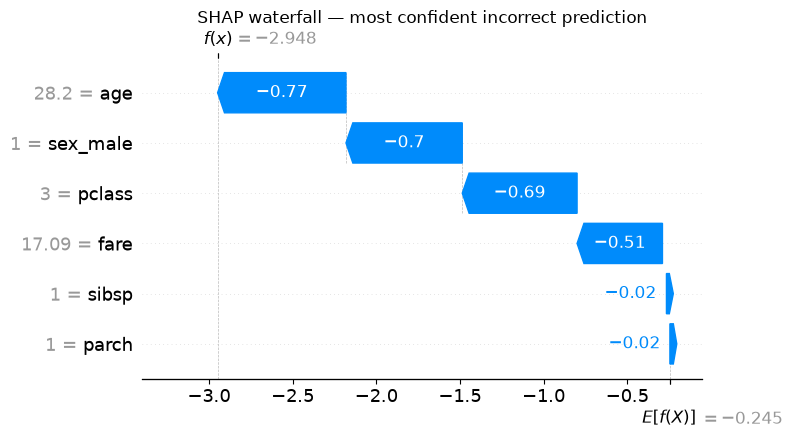


Write-up template:
The model predicted [predicted class] with a survival probability of [printed probability],
but the observed outcome was [actual label]. The waterfall shows that [name the largest
positive contributions] pushed the prediction toward survival, while [name the largest
negative contributions] pushed it away. The model can still be wrong because SHAP explains
how the model reached its output, not whether the model's learned pattern is correct for
this passenger. Next, I would inspect similar passengers and check whether the relevant
features, missing-value handling, and labels are reliable.



In [27]:
# TASK 10 — Explain the most confident wrong prediction (or most confident correct)
test_predictions = (test_prob >= 0.5).astype(int)
correct_mask = test_predictions == y_test.to_numpy()
wrong_positions = np.flatnonzero(~correct_mask)

if len(wrong_positions) > 0:
    # Confidence means distance from 0.5, regardless of which class was predicted.
    confidence = np.abs(test_prob - 0.5)
    idx = int(wrong_positions[np.argmax(confidence[wrong_positions])])
    status = "most confident incorrect prediction"
else:
    confidence = np.abs(test_prob - 0.5)
    idx = int(np.argmax(confidence))
    status = "most confident correct prediction; there were no errors on this test split"

print("Selected:", status)
print("Features:")
print(X_test.iloc[idx].to_string())
print("Actual survived:", int(y_test.iloc[idx]))
print(f"Predicted survival probability: {test_prob[idx]:.4f}")
print("Predicted class:", int(test_predictions[idx]))
print("Largest SHAP contributions:")
print(pd.Series(sv[idx], index=features).sort_values(key=np.abs, ascending=False))

one_exp = shap.Explanation(
    values=sv[idx],
    base_values=base_value,
    data=X_test.iloc[idx].to_numpy(),
    feature_names=features
)
shap.plots.waterfall(one_exp, max_display=len(features), show=False)
plt.title(f"SHAP waterfall — {status}")
plt.tight_layout()
plt.show()

print("""
Write-up template:
The model predicted [predicted class] with a survival probability of [printed probability],
but the observed outcome was [actual label]. The waterfall shows that [name the largest
positive contributions] pushed the prediction toward survival, while [name the largest
negative contributions] pushed it away. The model can still be wrong because SHAP explains
how the model reached its output, not whether the model's learned pattern is correct for
this passenger. Next, I would inspect similar passengers and check whether the relevant
features, missing-value handling, and labels are reliable.
""")

### Task 10 — Markdown answer

Use the actual passenger values, true outcome, predicted class/probability, and waterfall plot to fill the response. A confident error is especially useful because it shows the difference between **explaining a prediction** and **proving that prediction is correct**.

The waterfall explains which features moved the model's output up or down. It does not prove causation, show every missing piece of information, or establish why the real passenger survived or died.

**What to investigate next:** inspect similar cases, check data quality and labels, and look for systematic errors in the model's predictions. If the test split contains no errors, report that fact and explain the most confident correct case instead.

In [28]:
# OPTIONAL STRETCH — SHAP interaction values (can use substantial memory)
# Run only after the required tasks have completed successfully.
interaction_values = explainer.shap_interaction_values(X_test)
if isinstance(interaction_values, list):
    interaction_values = interaction_values[-1]
interaction_values = np.asarray(interaction_values)
if interaction_values.ndim == 4:
    interaction_values = interaction_values[:, :, :, -1]

# Mean absolute off-diagonal interaction strength for each feature pair.
mean_interactions = np.abs(interaction_values).mean(axis=0)
np.fill_diagonal(mean_interactions, 0)
pair_idx = np.unravel_index(np.argmax(mean_interactions), mean_interactions.shape)
print("Strongest interaction pair:",
      features[pair_idx[0]], "×", features[pair_idx[1]])
print("Mean absolute interaction:", mean_interactions[pair_idx])

Strongest interaction pair: pclass × fare
Mean absolute interaction: 0.12533759


### Optional stretch — interaction values

SHAP interaction values divide each prediction's contributions into main effects and pairwise interaction effects. This can help test whether the strongest numerical interaction matches the feature selected for coloring in a dependence plot. Interaction calculations can be memory-intensive, so run this only after the core notebook succeeds.